<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/yolo_exploracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚡ Explorando YOLO (Ultralytics) paso a paso
Detección, segmentación, pose, clasificación, OBB, tracking, soluciones, entrenamiento, validación y exportación.
Repositorio: https://github.com/ultralytics/ultralytics
> **Activa GPU:** Entorno de ejecución → Cambiar tipo de entorno → T4 GPU.

## 0. Instalación e imágenes de ejemplo

In [ ]:
!pip -q install ultralytics

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


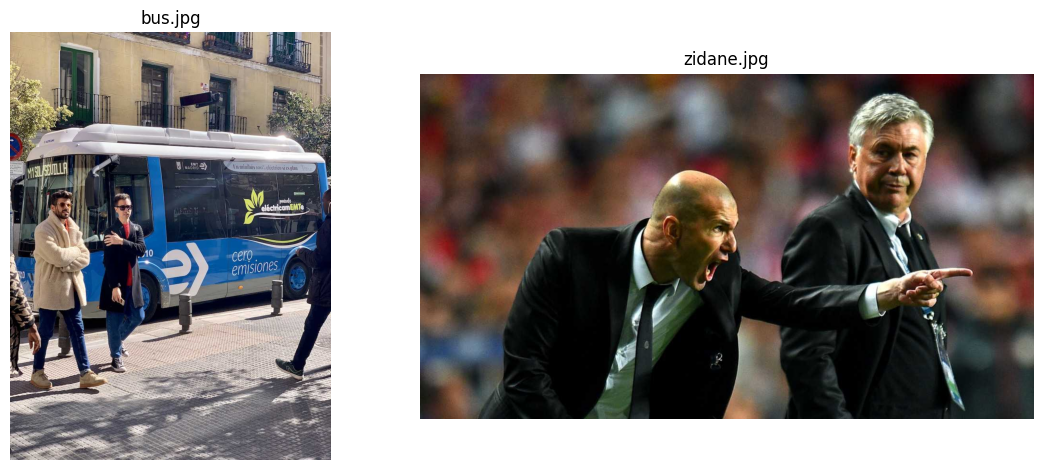

In [ ]:
import os, glob, time, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import YOLO
from ultralytics.utils import ASSETS
ultralytics.checks()

V = "yolo26"
BUS, ZID = str(ASSETS / "bus.jpg"), str(ASSETS / "zidane.jpg")

def show(images, titles=None, size=6):
    fig, ax = plt.subplots(1, len(images),
                           figsize=(size*len(images), size*0.8))
    ax = np.atleast_1d(ax)
    for i, im in enumerate(images):
        ax[i].imshow(im); ax[i].axis("off")
        if titles: ax[i].set_title(titles[i], fontsize=12)
    plt.tight_layout(); plt.show()

rgb = lambda r: r.plot()[:, :, ::-1]    # resultado anotado → RGB
show([cv2.imread(BUS)[:, :, ::-1],
      cv2.imread(ZID)[:, :, ::-1]], ["bus.jpg", "zidane.jpg"])

## 1. Detección de objetos


0: 640x640 4 persons, 1 bus, 9.0ms
1: 640x640 2 persons, 1 tie, 9.0ms
Speed: 42.7ms preprocess, 9.0ms inference, 16.5ms postprocess per image at shape (1, 3, 640, 640)


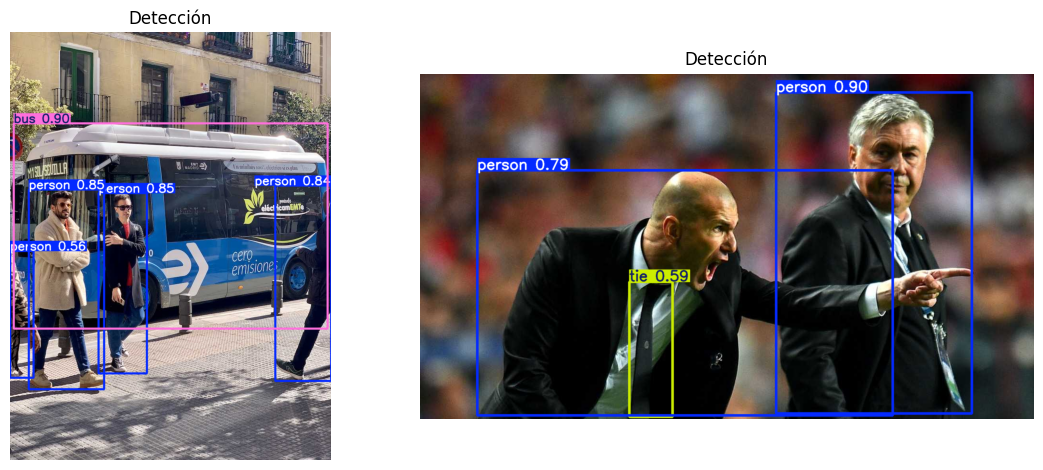

Campos de r.boxes: xyxy, conf, cls, xywh, xyxyn ...


,clase,confianza,caja (xyxy)
0,bus,0.903,"[10.0, 231.0, 801.0, 748.0]"
1,person,0.855,"[47.0, 398.0, 238.0, 902.0]"
2,person,0.845,"[224.0, 407.0, 346.0, 861.0]"
3,person,0.837,"[669.0, 387.0, 810.0, 880.0]"
4,person,0.557,"[0.0, 553.0, 60.0, 873.0]"


In [ ]:
model = YOLO(f"{V}n.pt")
res = model([BUS, ZID])
show([rgb(r) for r in res], ["Detección"]*2)

r = res[0]
print("Campos de r.boxes: xyxy, conf, cls, xywh, xyxyn ...")
pd.DataFrame({"clase": [r.names[int(c)] for c in r.boxes.cls],
              "confianza": r.boxes.conf.cpu().numpy().round(3),
              "caja (xyxy)": [b.round(0).tolist() for
                              b in r.boxes.xyxy.cpu().numpy()]})

### Parámetros clave: `conf`, `iou`, `classes`, `imgsz`

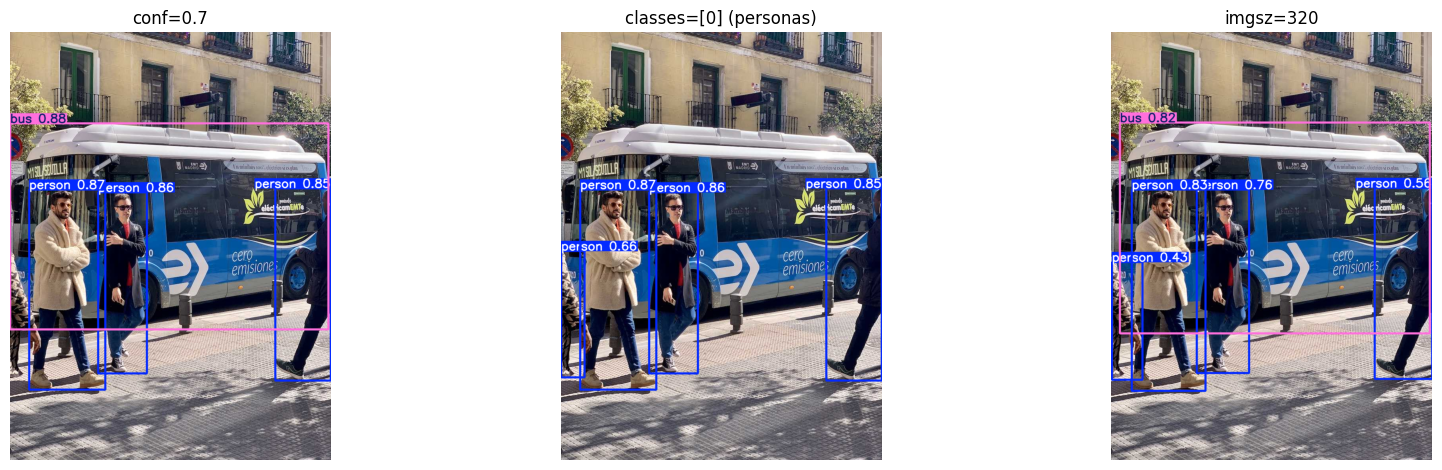

In [ ]:
a = model(BUS, conf=0.7, verbose=False)[0]            # solo detecciones muy seguras
b = model(BUS, classes=[0], verbose=False)[0]         # solo personas (clase 0)
c = model(BUS, imgsz=320, verbose=False)[0]           # menor resolución, más rápido
show([rgb(a), rgb(b), rgb(c)], ["conf=0.7", "classes=[0] (personas)", "imgsz=320"])

## 2. Segmentación de instancias

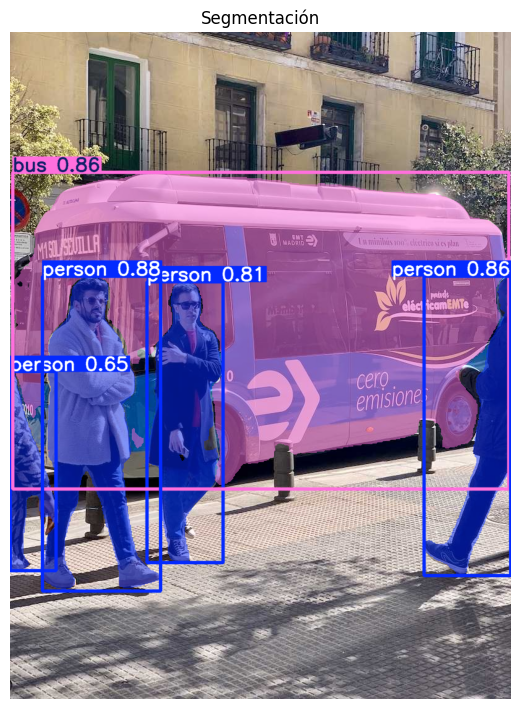

Máscaras: (5, 640, 480) | polígonos: 5


In [ ]:
seg = YOLO(f"{V}n-seg.pt")
r = seg(BUS, verbose=False)[0]
show([rgb(r)], ["Segmentación"], size=9)
print("Máscaras:", tuple(r.masks.data.shape),
      "| polígonos:", len(r.masks.xy))

## 3. Estimación de pose

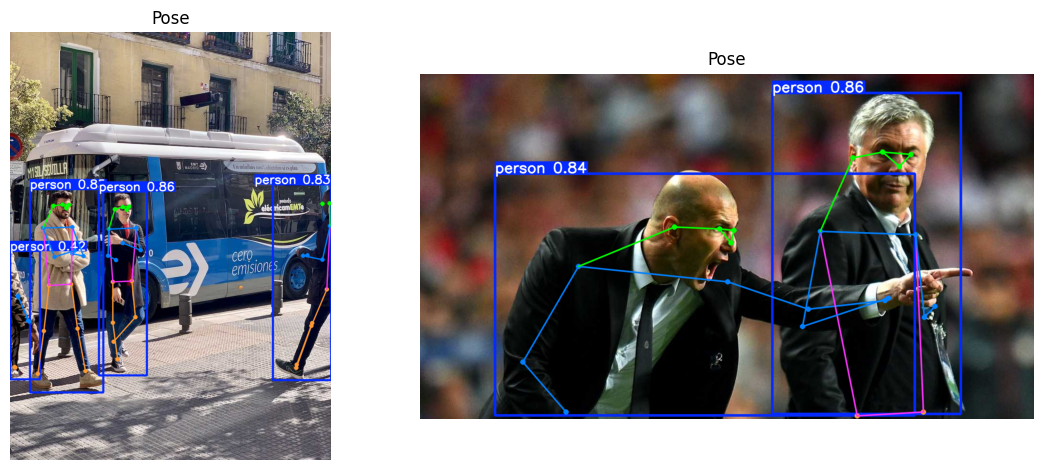

Keypoints por persona: (17, 2) (17 puntos x, y)


In [ ]:
pose = YOLO(f"{V}n-pose.pt")
res = pose([BUS, ZID], verbose=False)
show([rgb(r) for r in res], ["Pose"]*2)
print("Keypoints por persona:",
      tuple(res[0].keypoints.xy.shape[1:]), "(17 puntos x, y)")

## 4. Clasificación de imágenes

Top-5: [('minibus', 0.516), ('police_van', 0.369), ('trolleybus', 0.096), ('minivan', 0.006), ('ambulance', 0.003)]


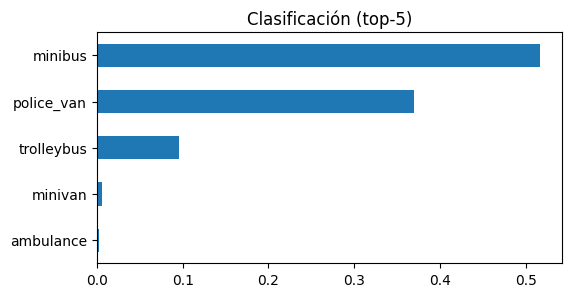

In [ ]:
cls = YOLO(f"{V}n-cls.pt")
r = cls(BUS, verbose=False)[0]
top = [(r.names[i], round(float(r.probs.data[i]), 3)) for i in r.probs.top5]
print("Top-5:", top)
pd.Series(dict(top)).sort_values().plot.barh(figsize=(6, 3), title="Clasificación (top-5)"); plt.show()

## 5. Cajas orientadas (OBB)

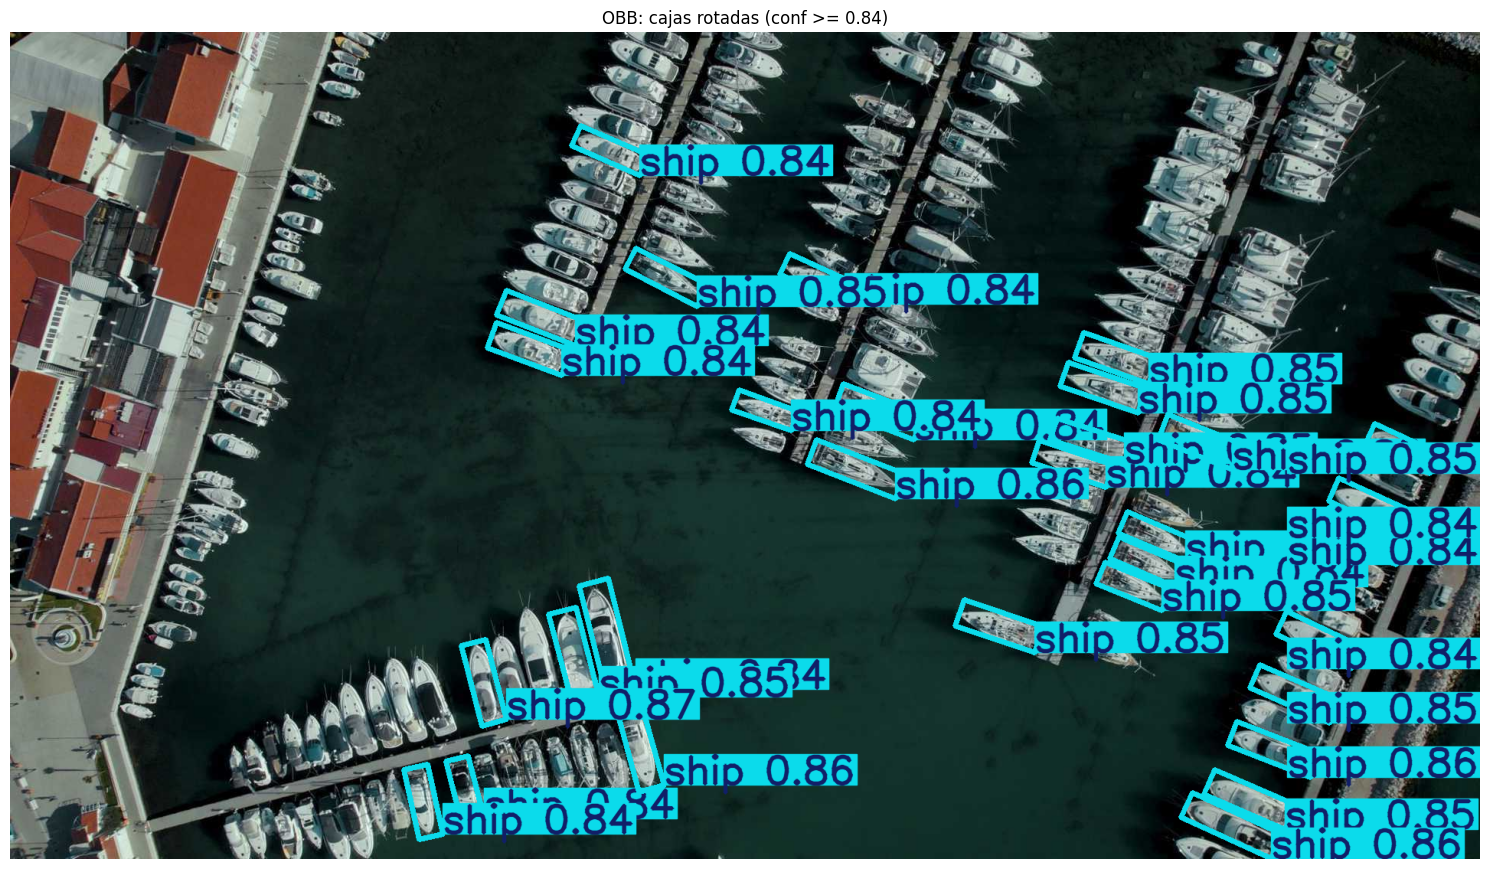

In [ ]:
try:
    !wget -q -nc https://ultralytics.com/images/boats.jpg
    obb = YOLO(f"{V}n-obb.pt")
    # Usamos conf=0.6 para filtrar y quedarnos solo con las cajas más seguras
    r = obb("boats.jpg", conf=0.84, verbose=False)[0]
    # Aumentamos el parámetro size a 15 para hacer la imagen más grande y visible
    show([rgb(r)], ["OBB: cajas rotadas (conf >= 0.84)"], size=15)
except Exception as e:
    print("OBB no disponible:", e)

## 6. Open-vocabulary: detectar lo que escribas (YOLO-World)

requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 37 packages in 740ms
Prepared 2 packages in 2.68s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 170MiB/s]


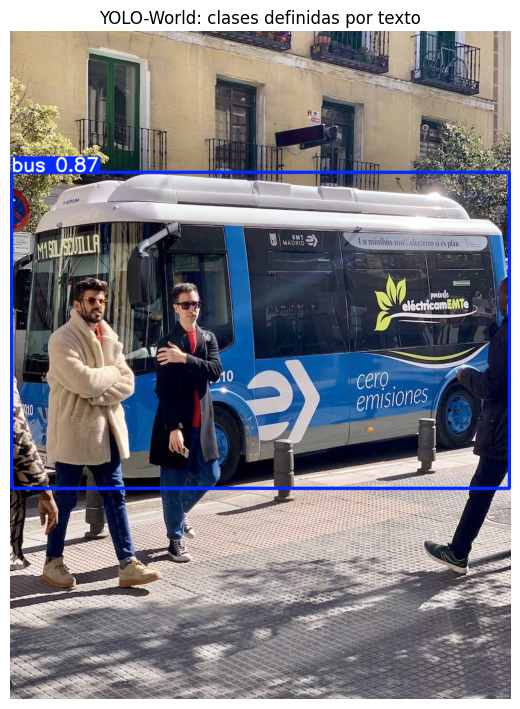

In [ ]:
try:
    w = YOLO("yolov8s-world.pt")
    w.set_classes(["bus", "backpack", "red sign"])
    r = w(BUS, verbose=False)[0]
    show([rgb(r)], ["YOLO-World: clases definidas por texto"], size=9)
except Exception as e:
    print("YOLO-World no disponible:", e)

## 7. Comparar tamaños de modelo (n, s, m)

,modelo,detecciones,ms/imagen,parámetros (M)
0,yolo26n,5,20.4,2.6
1,yolo26s,5,84.3,10.0
2,yolo26m,5,87.6,21.9


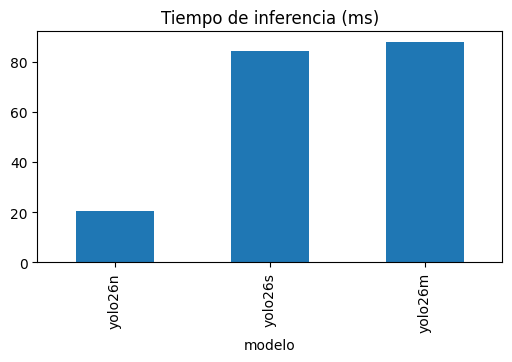

In [ ]:
rows = []
for s in ["n", "s", "m"]:
    m = YOLO(f"{V}{s}.pt"); m(BUS, verbose=False)                  # calentamiento
    t = time.time()
    for _ in range(5): out = m(BUS, verbose=False)
    rows.append([f"{V}{s}", len(out[0].boxes), round((time.time()-t)/5*1000, 1),
                 round(sum(p.numel() for p in m.model.parameters())/1e6, 1)])
df = pd.DataFrame(rows, columns=["modelo", "detecciones", "ms/imagen", "parámetros (M)"]); display(df)
df.set_index("modelo")["ms/imagen"].plot.bar(figsize=(6, 3), title="Tiempo de inferencia (ms)"); plt.show()

## 8. Video y tracking (ByteTrack)

In [ ]:
USE_MY_VIDEO = True   # ← True para subir tu propio video
VIDEO_IN = "input.mp4"
if USE_MY_VIDEO:
    from google.colab import files
    up = files.upload(); os.rename(list(up.keys())[0], VIDEO_IN)
else:
    ok = False
    for u in ["https://github.com/ultralytics/assets/releases/download/v0.0.0/solutions_ci_demo.mp4",
              "https://github.com/ultralytics/assets/releases/download/v0.0.0/people-walking.mp4"]:
        os.system(f"wget -q -O {VIDEO_IN} {u}")
        if os.path.exists(VIDEO_IN) and os.path.getsize(VIDEO_IN) > 100_000: ok = True; break
    if not ok:   # plan B: video corto con imágenes de ejemplo
        vw = cv2.VideoWriter(VIDEO_IN, cv2.VideoWriter_fourcc(*"mp4v"), 10, (640, 480))
        for p in [BUS, ZID]:
            for _ in range(40): vw.write(cv2.resize(cv2.imread(p), (640, 480)))
        vw.release()
cap = cv2.VideoCapture(VIDEO_IN); print("Video:", int(cap.get(3)), "x", int(cap.get(4)), "|", int(cap.get(7)), "frames"); cap.release()

Saving 854671-hd_1920_1080_25fps.mp4 to 854671-hd_1920_1080_25fps.mp4
Video: 1920 x 1080 | 1501 frames


In [ ]:
tr = YOLO(f"{V}n.pt")

tr.track(source=VIDEO_IN, tracker="bytetrack.yaml", persist=True, save=True,
         project="runs_demo", name="track", exist_ok=True, verbose=False)

out = glob.glob("runs/detect/runs_demo/track/*.avi") + glob.glob("runs/detect/runs_demo/track/*.mp4") + glob.glob("runs_demo/track/*.avi") + glob.glob("runs_demo/track/*.mp4")

if len(out) > 0:
    !ffmpeg -y -loglevel error -i {out[0]} -vcodec libx264 track.mp4
    from IPython.display import HTML
    from base64 import b64encode
    data = b64encode(open("track.mp4", "rb").read()).decode()
    display(HTML(f'<video width=560 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))
else:
    print("No se encontró el video generado. Verifica que la inferencia se haya completado correctamente.")

### IDs de seguimiento por fotograma

In [ ]:
rows = []
for i, r in enumerate(tr.track(source=VIDEO_IN, stream=True, persist=True, verbose=False)):
    if r.boxes.id is not None:
        rows.append([i, r.boxes.id.int().tolist()[:6], [r.names[int(c)] for c in r.boxes.cls][:6]])
    if i >= 30: break
pd.DataFrame(rows, columns=["frame", "ids", "clases"]).head(8)

,frame,ids,clases
0,0,"[7, 589]","[bus, car]"
1,1,"[7, 589, 651, 652, 653, 654]","[bus, car, car, car, car, car]"
2,2,"[7, 589, 651, 652, 653, 654]","[bus, car, car, car, car, car]"
3,3,"[7, 589, 651, 652, 653, 654]","[bus, car, car, car, car, car]"
4,4,"[7, 589, 651, 652, 653, 654]","[bus, car, car, car, car, car]"
5,5,"[7, 589, 651, 652, 653, 654]","[bus, car, car, car, car, car]"
6,6,"[7, 589, 651, 652, 653, 654]","[bus, car, car, car, car, car]"
7,7,"[7, 589, 651, 652, 653, 654]","[bus, car, car, car, car, car]"


## 9. Soluciones listas: contador de objetos

In [ ]:
try:
    from ultralytics import solutions
    cap = cv2.VideoCapture(VIDEO_IN)
    W, H = int(cap.get(3)), int(cap.get(4)); fps = cap.get(5) or 10
    counter = solutions.ObjectCounter(show=False, region=[(0, H//2), (W, H//2)], model=f"{V}n.pt")
    vw = cv2.VideoWriter("count_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
    while True:
        ok, fr = cap.read()
        if not ok: break
        vw.write(counter(fr).plot_im)
    cap.release(); vw.release()
    !ffmpeg -y -loglevel error -i count_raw.mp4 -vcodec libx264 count.mp4
    data = b64encode(open("count.mp4", "rb").read()).decode()
    display(HTML(f'<video width=560 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))
except Exception as e:
    print("Solutions no disponible en esta versión:", e)

## 10. Validar y entrenar (dataset de ejemplo coco8)

In [ ]:
m = YOLO(f"{V}n.pt")
v = m.val(data="coco8.yaml", verbose=False, plots=False)
pd.DataFrame({"métrica": ["mAP50-95", "mAP50", "precisión", "recall"],
              "valor": [v.box.map, v.box.map50, v.box.mp, v.box.mr]}).round(3)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs

WARNING ⚠️ Dataset 'coco8.yaml' images not found, missing path '/content/datasets/coco8/images/val'
Unzipping /content/datasets/coco8.zip to /content/datasets/coco8...: 100% ━━━━━━━━━━━━ 25/25 3.9Kfiles/s 0.0s
Dataset download success ✅ (0.4s), saved to /content/datasets

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1030.7±694.1 MB/s, size: 54.0 KB)
val: Scanning /content/datasets/coco8/labels/val... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.5Kit/s 0.0s
val: New cache created: /content/datasets/coco8/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.3it/s 0.2s
                   all          4         17      0.551      0.962      0.943      0.669
Speed: 0.7ms preprocess, 15.6ms inference, 0.0ms loss, 1.9ms postprocess

,métrica,valor
0,mAP50-95,0.669
1,mAP50,0.943
2,precisión,0.551
3,recall,0.962


In [ ]:
m = YOLO(f"{V}n.pt")
m.train(data="coco8.yaml", epochs=10, imgsz=640, batch=8, plots=True,
        project="runs_demo", name="train", exist_ok=True)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0, 16, 17, 20, 25, 58])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ea8a39eba70>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

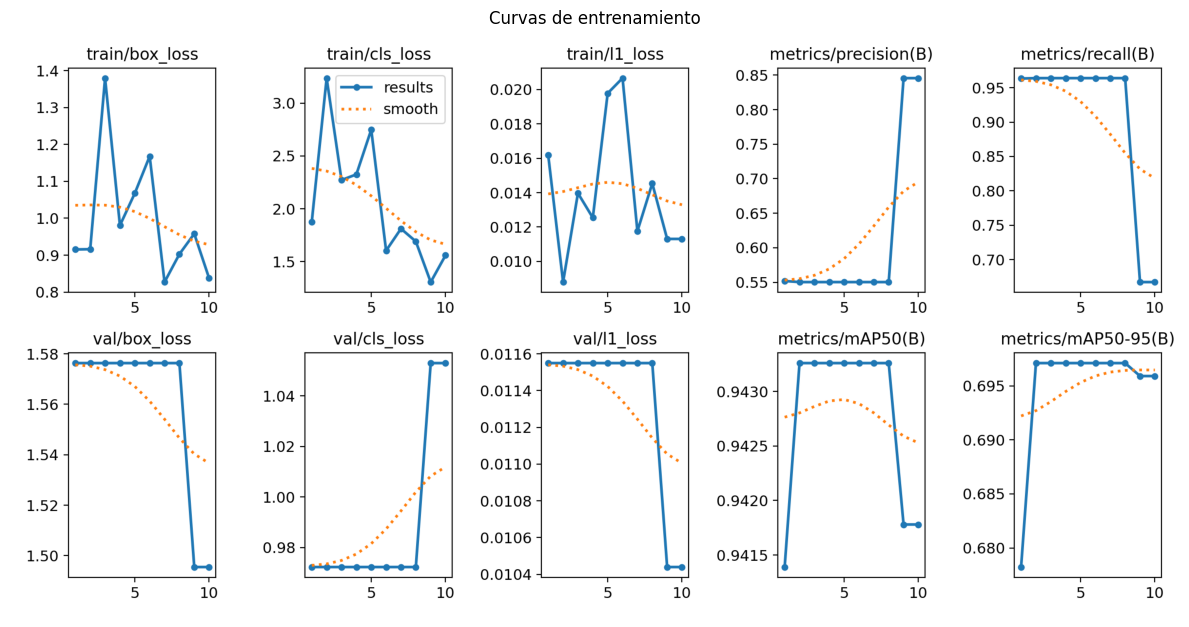

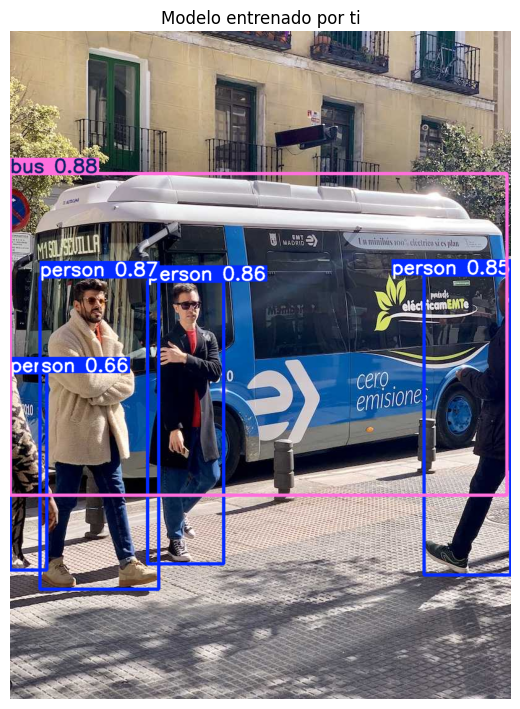

In [ ]:
res_img = cv2.imread("runs/detect/runs_demo/train/results.png")
best = YOLO("runs/detect/runs_demo/train/weights/best.pt")
show([res_img[:, :, ::-1]], ["Curvas de entrenamiento"], size=12)
show([rgb(best(BUS, verbose=False)[0])], ["Modelo entrenado por ti"], size=9)

## 11. Exportar a otros formatos

In [ ]:
path = best.export(format="onnx")           # también: torchscript, openvino, engine (TensorRT), tflite, coreml...
onnx_model = YOLO(path)
show([rgb(onnx_model(BUS, verbose=False)[0])], ["Inferencia con el modelo ONNX"], size=9)
print("Exportado:", path, "|", round(os.path.getsize(path)/1e6, 1), "MB")

## ✅ Resumen
| Tarea | Modelo / función |
|---|---|
| Detección | `yolo11n.pt` · `model(img)` |
| Segmentación | `yolo11n-seg.pt` |
| Pose | `yolo11n-pose.pt` |
| Clasificación | `yolo11n-cls.pt` |
| OBB | `yolo11n-obb.pt` |
| Tracking | `model.track(...)` |
| Soluciones | `solutions.ObjectCounter` |
| Entrenar / validar / exportar | `train()` · `val()` · `export()` |